# Human & PPE Detection with Safety Zone Alert

**Final, organized notebook for the assignment**

This notebook uses the trained custom YOLOv8 model to:
- detect people and helmets in the supplied videos;
- associate helmet detections with individual people;
- check whether each person's bottom-centre point is inside a configured safety ROI;
- track people with ByteTrack;
- annotate safe and alert conditions and save output videos.

**Status rules**
- **Red – ROI INTRUSION:** the person's foot point is inside the configured ROI.
- **Red – HELMET NOT DETECTED:** no helmet detection was associated with that person.
- **Green – SAFE:** a helmet was associated and the person is outside the ROI.

> Important: The ROI coordinates below are demonstration boundaries selected during development. Confirm them with the assignment team/site safety owner before treating them as official hazard boundaries. “Helmet not detected” means the model/matching logic did not find a helmet; it is not proof that a person is definitely not wearing one.

## 1. Environment, project paths, and input-video inspection

Run this cell first. It locates the project whether the notebook is opened from the project root or its `notebooks` folder.

In [7]:
import sys
import cv2
import torch
import ultralytics
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO
import time

CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "models").is_dir():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "models").is_dir():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate the project folder. Open this notebook from "
        "the assignment root or its notebooks folder."
    )

MODEL_PATH = PROJECT_ROOT / "models" / "human_ppe_best.pt"
CUSTOM_MODEL_PATH = MODEL_PATH
INPUT_VIDEO_DIR = PROJECT_ROOT / "dataset" / "input_videos"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

video_files = sorted(
    p for p in INPUT_VIDEO_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".mp4", ".avi", ".mov", ".mkv"}
) if INPUT_VIDEO_DIR.exists() else []

print("========== ENVIRONMENT ==========")
print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("OpenCV:", cv2.__version__)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

print("\n========== PROJECT ==========")
print("Project root:", PROJECT_ROOT)
print("Model exists:", MODEL_PATH.exists())
print("Input folder exists:", INPUT_VIDEO_DIR.exists())
print("Output folder:", OUTPUT_DIR)
print("Number of input videos:", len(video_files))

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Trained model not found: {MODEL_PATH}")

if len(video_files) != 4:
    raise ValueError(
        f"Expected 4 input videos, but found {len(video_files)} in {INPUT_VIDEO_DIR}"
    )

for i, video_path in enumerate(video_files):
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        print(f"WARNING: Could not open Video {i}: {video_path.name}")
        cap.release()
        continue

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration = frame_count / fps if fps > 0 else 0

    print(f"\nVideo {i}: {video_path.name}")
    print(f"  Resolution: {width} x {height}")
    print(f"  FPS: {fps:.2f}")
    print(f"  Frames: {frame_count}")
    print(f"  Duration: {duration:.2f} seconds")
    cap.release()

print("\nEnvironment and input inspection completed.")

========== ENVIRONMENT ==========
Python: 3.11.9
Python executable: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection\.venv_ppe_safety_cv311\Scripts\python.exe
OpenCV: 5.0.0
PyTorch: 2.15.0+cpu
Ultralytics: 8.4.211
CUDA available: False

========== PROJECT ==========
Project root: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection
Model exists: True
Input folder exists: True
Output folder: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection\outputs
Number of input videos: 4

Video 0: vlc-record-2026-02-25-18h53m17s-25-02-2026_shift_a.mp4-.mp4
  Resolution: 1280 x 720
  FPS: 5.00
  Frames: 173
  Duration: 34.60 seconds

Video 1: vlc-record-2026-03-31-10h35m01s-24-03-2026_shift_a.mp4-.mp4
  Resolution: 1310 x 608
  FPS: 10.00
  Frames: 400
  Duration: 40.00 seconds

Video 2: vlc-record-2026-03-31-11h42m54s-27-03-2026_shift_a.mp4-.mp4
  Resolution: 1310 x 608
  FPS: 9.00
  Frames: 153
  Duration: 17.00 seconds

Video 3: vlc-record-2

## 2. Load the final trained model

The model is expected to contain the two classes `Helmet` and `Person`.

In [8]:
ppe_model = YOLO(str(MODEL_PATH))
print("Model loaded successfully.")
print("Model classes:", ppe_model.names)

class_names = {int(k): str(v).lower() for k, v in ppe_model.names.items()}
PERSON_CLASS_ID = next((k for k, v in class_names.items() if v == "person"), None)
HELMET_CLASS_ID = next((k for k, v in class_names.items() if v == "helmet"), None)

if PERSON_CLASS_ID is None or HELMET_CLASS_ID is None:
    raise ValueError(
        "The trained model must contain both 'Person' and 'Helmet' classes. "
        f"Found: {ppe_model.names}"
    )

print("Person class ID:", PERSON_CLASS_ID)
print("Helmet class ID:", HELMET_CLASS_ID)

Model loaded successfully.
Model classes: {0: 'Helmet', 1: 'Person'}
Person class ID: 1
Helmet class ID: 0


## 3. Visual inspection of sample frames

This displays three sample positions from each input video to check the camera views.

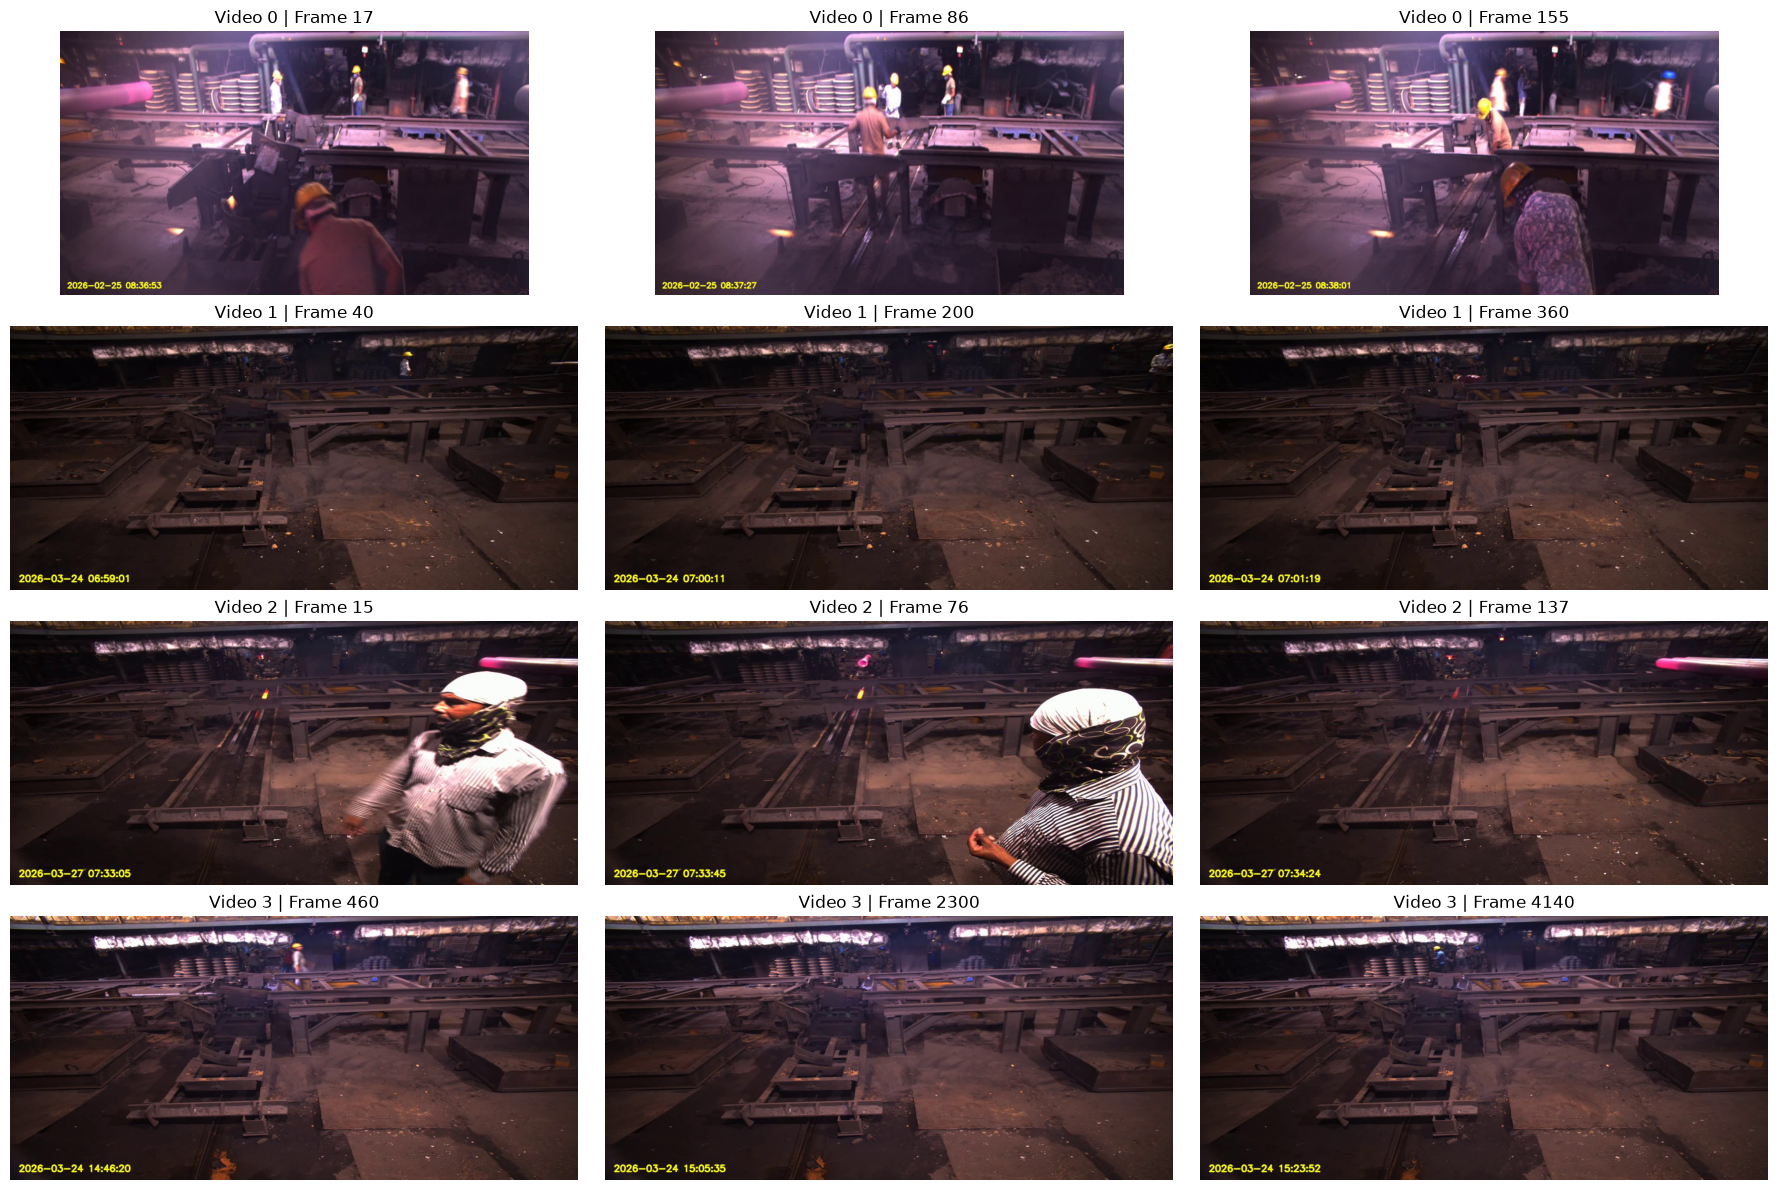

In [9]:
sample_positions = [0.10, 0.50, 0.90]
fig, axes = plt.subplots(len(video_files), len(sample_positions), figsize=(18, 12))
axes = np.asarray(axes).reshape(len(video_files), len(sample_positions))

for row, video_path in enumerate(video_files):
    cap = cv2.VideoCapture(str(video_path))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    for col, position in enumerate(sample_positions):
        frame_number = min(max(int(total_frames * position), 0), max(total_frames - 1, 0))
        cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
        success, frame = cap.read()

        if success:
            axes[row, col].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
            axes[row, col].set_title(f"Video {row} | Frame {frame_number}")
        else:
            axes[row, col].set_title("Frame could not be read")
        axes[row, col].axis("off")

    cap.release()

plt.tight_layout()
plt.show()

## 4. Test custom-model detections on representative frames

This is a visual sanity check before processing complete videos.

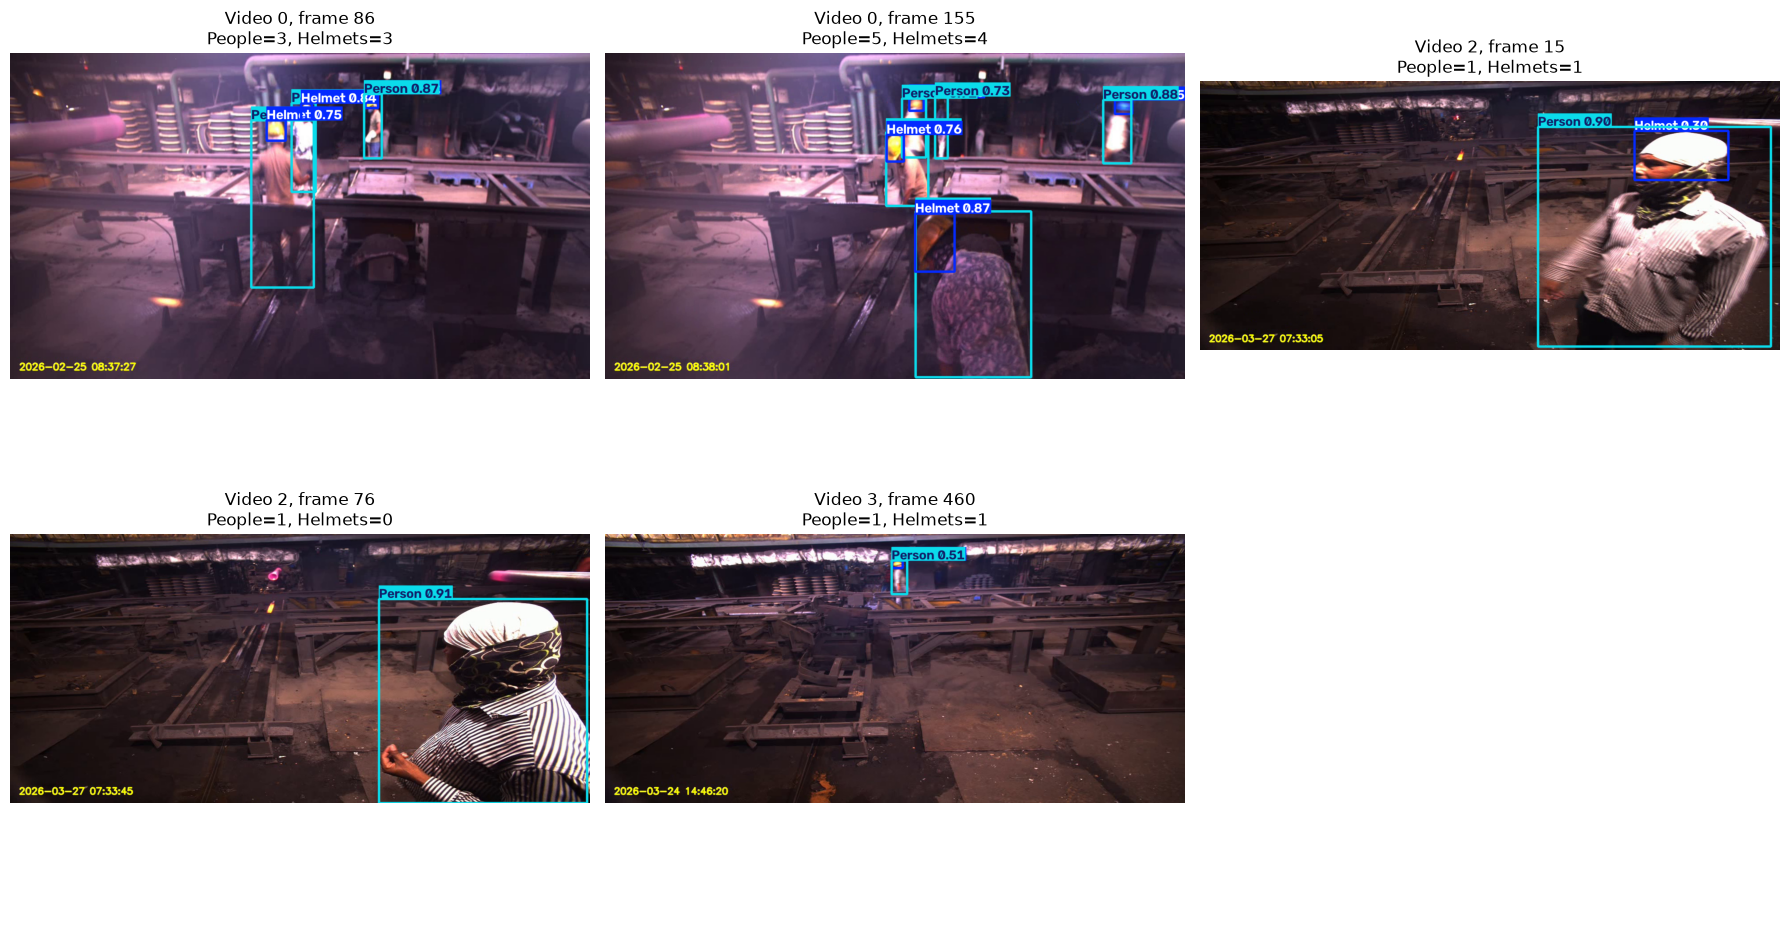

In [10]:
test_cases = [
    (0, 86),
    (0, 155),
    (2, 15),
    (2, 76),
    (3, 460)
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, (video_index, frame_number) in zip(axes, test_cases):
    cap = cv2.VideoCapture(str(video_files[video_index]))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    success, frame = cap.read()
    cap.release()

    if not success:
        ax.set_title(f"Video {video_index}, frame {frame_number}: unavailable")
        ax.axis("off")
        continue

    result = ppe_model.predict(
        source=frame, imgsz=640, conf=0.25, device="cpu", verbose=False
    )[0]

    counts = {"person": 0, "helmet": 0}
    if result.boxes is not None:
        for box in result.boxes:
            name = class_names[int(box.cls[0])]
            if name in counts:
                counts[name] += 1

    annotated = result.plot()
    ax.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax.set_title(
        f"Video {video_index}, frame {frame_number}\n"
        f"People={counts['person']}, Helmets={counts['helmet']}"
    )
    ax.axis("off")

for ax in axes[len(test_cases):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Define and visualize safety regions (ROI)

The first input video uses its own ROI. Videos 1, 2, and 3 use the second ROI. Coordinates are in pixels and must fit each corresponding video frame.

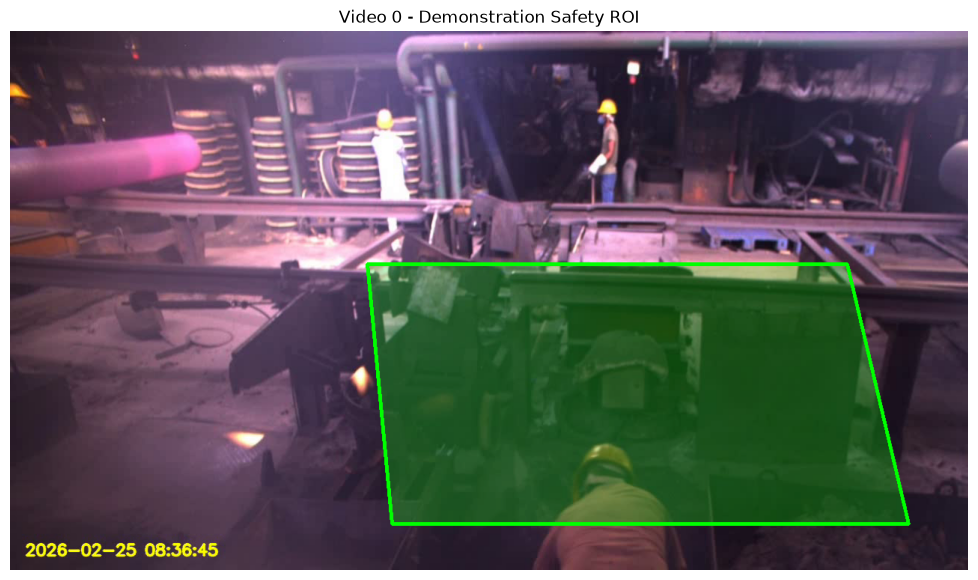

ROI coordinates: [[477, 311], [1118, 311], [1200, 658], [510, 658]]


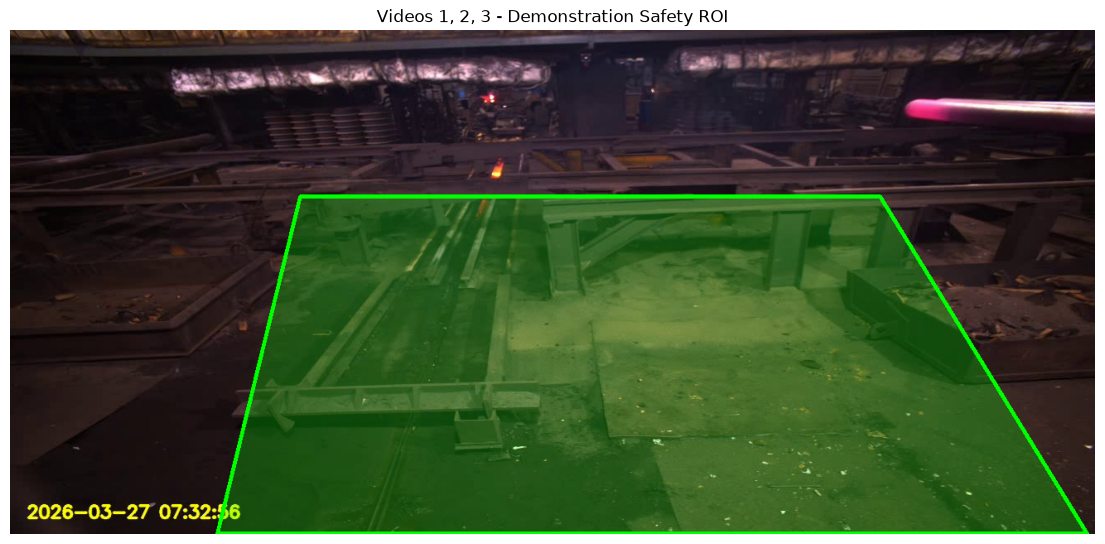

ROI coordinates: [[350, 200], [1050, 200], [1300, 607], [250, 607]]


In [11]:
roi_video_0 = np.array([
    [477, 311],
    [1118, 311],
    [1200, 658],
    [510, 658]
], dtype=np.int32)

roi_video_1_2_3 = np.array([
    [350, 200],
    [1050, 200],
    [1300, 607],
    [250, 607]
], dtype=np.int32)

def show_roi(video_index, roi, title):
    cap = cv2.VideoCapture(str(video_files[video_index]))
    success, frame = cap.read()
    cap.release()

    if not success:
        raise RuntimeError(f"Could not read a frame from Video {video_index}")

    h, w = frame.shape[:2]
    if np.any(roi[:, 0] < 0) or np.any(roi[:, 0] >= w) or np.any(roi[:, 1] < 0) or np.any(roi[:, 1] >= h):
        raise ValueError(f"ROI coordinates exceed Video {video_index} frame size {w}x{h}")

    overlay = frame.copy()
    cv2.fillPoly(overlay, [roi], (0, 255, 0))
    display_frame = cv2.addWeighted(frame, 0.75, overlay, 0.25, 0)
    cv2.polylines(display_frame, [roi], True, (0, 255, 0), 3)

    plt.figure(figsize=(14, 7))
    plt.imshow(cv2.cvtColor(display_frame, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

    print("ROI coordinates:", roi.tolist())

show_roi(0, roi_video_0, "Video 0 - Demonstration Safety ROI")
show_roi(2, roi_video_1_2_3, "Videos 1, 2, 3 - Demonstration Safety ROI")

## 6. Associate helmet detections with people

A helmet is considered associated when at least 30% of its area overlaps the upper 35% of a person's bounding box. Each helmet and person can be matched at most once.

In [12]:
def associate_helmets(person_boxes, helmet_boxes, threshold=0.30):
    matches = {}
    used_helmets = set()
    candidates = []

    for person_idx, person in enumerate(person_boxes):
        px1, py1, px2, py2 = person
        head_y2 = py1 + 0.35 * (py2 - py1)

        for helmet_idx, helmet in enumerate(helmet_boxes):
            hx1, hy1, hx2, hy2 = helmet

            ix1 = max(px1, hx1)
            iy1 = max(py1, hy1)
            ix2 = min(px2, hx2)
            iy2 = min(head_y2, hy2)

            intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
            helmet_area = max(1, (hx2 - hx1) * (hy2 - hy1))
            overlap_ratio = intersection / helmet_area

            if overlap_ratio >= threshold:
                candidates.append((overlap_ratio, person_idx, helmet_idx))

    candidates.sort(reverse=True)

    for score, person_idx, helmet_idx in candidates:
        if person_idx not in matches and helmet_idx not in used_helmets:
            matches[person_idx] = helmet_idx
            used_helmets.add(helmet_idx)

    return matches

## 7. Process one video: detection, tracking, helmet association, and ROI alerts

The function below creates a fresh model instance for each video so ByteTrack IDs restart cleanly between videos. Status totals are **person-frame counts**, not unique people or unique incidents.

In [13]:
def process_safety_video(video_index, overwrite=True):
    if not 0 <= video_index < len(video_files):
        raise IndexError(f"Invalid video index: {video_index}")

    video_path = video_files[video_index]
    roi = roi_video_0.copy() if video_index == 0 else roi_video_1_2_3.copy()
    output_path = OUTPUT_DIR / f"video_{video_index}_safety_output.mp4"

    if output_path.exists() and not overwrite:
        print(f"Skipping existing output: {output_path}")
        return output_path

    model = YOLO(str(CUSTOM_MODEL_PATH))
    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"Could not open input video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    if fps <= 0 or width <= 0 or height <= 0:
        cap.release()
        raise RuntimeError(f"Invalid video metadata for: {video_path}")

    if np.any(roi[:, 0] < 0) or np.any(roi[:, 0] >= width) or np.any(roi[:, 1] < 0) or np.any(roi[:, 1] >= height):
        cap.release()
        raise ValueError(f"ROI does not fit Video {video_index} ({width}x{height})")

    writer = cv2.VideoWriter(
        str(output_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps,
        (width, height)
    )

    if not writer.isOpened():
        cap.release()
        raise RuntimeError(f"Could not create output video: {output_path}")

    counts = {"safe": 0, "intrusion": 0, "helmet_alert": 0}
    frame_count = 0

    try:
        while True:
            ret, frame = cap.read()
            if not ret:
                break

            results = model.track(
                source=frame,
                persist=True,
                tracker="bytetrack.yaml",
                conf=0.25,
                imgsz=640,
                device="cpu",
                verbose=False
            )
            result = results[0]

            person_boxes, helmet_boxes, person_ids = [], [], []

            if result.boxes is not None:
                for box in result.boxes:
                    class_id = int(box.cls[0])
                    coords = box.xyxy[0].cpu().numpy().astype(int)

                    if class_id == PERSON_CLASS_ID:
                        person_boxes.append(coords)
                        track_id = -1
                        if box.id is not None:
                            track_id = int(box.id[0])
                        person_ids.append(track_id)

                    elif class_id == HELMET_CLASS_ID:
                        helmet_boxes.append(coords)

            matches = associate_helmets(person_boxes, helmet_boxes)

            for person_idx, person in enumerate(person_boxes):
                x1, y1, x2, y2 = map(int, person)
                foot_point = (int((x1 + x2) / 2), int(y2))
                inside_roi = cv2.pointPolygonTest(roi, foot_point, False) >= 0
                helmet_detected = person_idx in matches

                if inside_roi:
                    color = (0, 0, 255)
                    status = "ROI INTRUSION"
                    counts["intrusion"] += 1
                elif not helmet_detected:
                    color = (0, 0, 255)
                    status = "HELMET NOT DETECTED"
                    counts["helmet_alert"] += 1
                else:
                    color = (0, 255, 0)
                    status = "SAFE"
                    counts["safe"] += 1

                cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
                cv2.putText(
                    frame,
                    f"ID {person_ids[person_idx]}: {status}",
                    (x1, max(25, y1 - 10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.55,
                    color,
                    2
                )

            cv2.polylines(frame, [roi], True, (255, 255, 0), 2)
            frame_count += 1
            cv2.putText(
                frame,
                f"Frame: {frame_count}/{total_frames}",
                (20, 30),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 255, 255),
                2
            )
            writer.write(frame)

            if frame_count % 200 == 0:
                print(f"Video {video_index}: {frame_count}/{total_frames} frames")

    finally:
        cap.release()
        writer.release()

    if frame_count == 0 or not output_path.exists() or output_path.stat().st_size == 0:
        raise RuntimeError(f"Output generation failed for Video {video_index}")

    print(f"\nVideo {video_index} completed")
    print("Frames processed:", frame_count)
    print("Safe person-frames:", counts["safe"])
    print("ROI intrusion person-frames:", counts["intrusion"])
    print("Helmet alert person-frames:", counts["helmet_alert"])
    print("Output:", output_path)
    print("Output size (MB):", round(output_path.stat().st_size / (1024 * 1024), 2))

    return output_path, counts

## 8. Run the complete pipeline on all four input videos

**This is the main processing step.** It may take several minutes on a CPU, especially for the longest video. Run it once after the setup, ROI, and helmet-association cells have completed successfully.

In [14]:
processing_results = {}

for video_index in range(len(video_files)):
    output_path, counts = process_safety_video(video_index, overwrite=True)
    processing_results[video_index] = {
        "output_path": str(output_path),
        **counts
    }

print("\nAll four videos processed.")


Video 0 completed
Frames processed: 173
Safe person-frames: 301
ROI intrusion person-frames: 100
Helmet alert person-frames: 156
Output: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection\outputs\video_0_safety_output.mp4
Output size (MB): 5.68
Video 1: 200/400 frames
Video 1: 400/400 frames

Video 1 completed
Frames processed: 400
Safe person-frames: 44
ROI intrusion person-frames: 166
Helmet alert person-frames: 70
Output: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection\outputs\video_1_safety_output.mp4
Output size (MB): 8.71

Video 2 completed
Frames processed: 153
Safe person-frames: 20
ROI intrusion person-frames: 42
Helmet alert person-frames: 55
Output: c:\Users\Administrator\Desktop\Assignments\Human_PPE_Safety_Detection\outputs\video_2_safety_output.mp4
Output size (MB): 7.51
Video 3: 200/4600 frames
Video 3: 400/4600 frames
Video 3: 600/4600 frames
Video 3: 800/4600 frames
Video 3: 1000/4600 frames
Video 3: 1200/4600 frames
Video 3: 1

## 9. Complete-pipeline benchmark (first 200 frames of Video 3)

This benchmark includes tracking, helmet association, ROI checking, drawing, and video writing. It is a sample benchmark on this machine, not a guarantee of real-time performance for every video or device.

In [15]:
benchmark_video_index = 3
benchmark_video_path = video_files[benchmark_video_index]
benchmark_roi = roi_video_1_2_3.copy()
benchmark_model = YOLO(str(CUSTOM_MODEL_PATH))

cap = cv2.VideoCapture(str(benchmark_video_path))
source_fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

benchmark_output = OUTPUT_DIR / "benchmark_video3_200frames.mp4"
writer = cv2.VideoWriter(
    str(benchmark_output),
    cv2.VideoWriter_fourcc(*"mp4v"),
    source_fps,
    (width, height)
)

if not cap.isOpened() or not writer.isOpened():
    cap.release()
    writer.release()
    raise RuntimeError("Could not open benchmark input or output video.")

frames_to_test = 200
frames_processed = 0
benchmark_start = time.perf_counter()

try:
    while frames_processed < frames_to_test:
        ret, frame = cap.read()
        if not ret:
            break

        result = benchmark_model.track(
            source=frame,
            persist=True,
            tracker="bytetrack.yaml",
            conf=0.25,
            imgsz=640,
            device="cpu",
            verbose=False
        )[0]

        person_boxes, helmet_boxes, person_ids = [], [], []

        if result.boxes is not None:
            for box in result.boxes:
                class_id = int(box.cls[0])
                coords = box.xyxy[0].cpu().numpy().astype(int)

                if class_id == PERSON_CLASS_ID:
                    person_boxes.append(coords)
                    person_ids.append(int(box.id[0]) if box.id is not None else -1)
                elif class_id == HELMET_CLASS_ID:
                    helmet_boxes.append(coords)

        matches = associate_helmets(person_boxes, helmet_boxes)

        for person_idx, person in enumerate(person_boxes):
            x1, y1, x2, y2 = map(int, person)
            foot_point = (int((x1 + x2) / 2), int(y2))
            inside_roi = cv2.pointPolygonTest(benchmark_roi, foot_point, False) >= 0
            helmet_detected = person_idx in matches

            if inside_roi:
                color, status = (0, 0, 255), "ROI INTRUSION"
            elif not helmet_detected:
                color, status = (0, 0, 255), "HELMET NOT DETECTED"
            else:
                color, status = (0, 255, 0), "SAFE"

            cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
            cv2.putText(
                frame, f"ID {person_ids[person_idx]}: {status}",
                (x1, max(25, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2
            )

        cv2.polylines(frame, [benchmark_roi], True, (255, 255, 0), 2)
        writer.write(frame)
        frames_processed += 1
finally:
    cap.release()
    writer.release()

elapsed = time.perf_counter() - benchmark_start
pipeline_fps = frames_processed / elapsed if elapsed > 0 else 0

print("COMPLETE PIPELINE BENCHMARK")
print("---------------------------")
print("Frames processed:", frames_processed)
print("Total time (seconds):", round(elapsed, 2))
print("Source FPS:", source_fps)
print("Complete pipeline FPS:", round(pipeline_fps, 2))
print("Benchmark output exists:", benchmark_output.exists())

COMPLETE PIPELINE BENCHMARK
---------------------------
Frames processed: 200
Total time (seconds): 20.92
Source FPS: 10.0
Complete pipeline FPS: 9.56
Benchmark output exists: True


## 10. Validate generated output videos

Check that each output can be opened and that its first frame can be decoded.

In [16]:
validation_rows = []

for i in range(len(video_files)):
    output_path = OUTPUT_DIR / f"video_{i}_safety_output.mp4"
    cap = cv2.VideoCapture(str(output_path))

    opened = cap.isOpened()
    if opened:
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        ret, first_frame = cap.read()
        first_frame_readable = bool(ret and first_frame is not None)
    else:
        fps, frame_count, width, height = 0, 0, 0, 0
        first_frame_readable = False

    cap.release()

    row = {
        "video": i,
        "exists": output_path.exists(),
        "opens": opened,
        "fps": fps,
        "frames": frame_count,
        "resolution": f"{width}x{height}",
        "first_frame_readable": first_frame_readable,
        "size_mb": round(output_path.stat().st_size / (1024 * 1024), 2)
                   if output_path.exists() else 0
    }
    validation_rows.append(row)
    print(row)

if not all(r["exists"] and r["opens"] and r["first_frame_readable"] for r in validation_rows):
    print("\nWARNING: At least one output video failed validation.")
else:
    print("\nAll four output videos passed basic file/readability validation.")

{'video': 0, 'exists': True, 'opens': True, 'fps': 5.0, 'frames': 173, 'resolution': '1280x720', 'first_frame_readable': True, 'size_mb': 5.68}
{'video': 1, 'exists': True, 'opens': True, 'fps': 10.0, 'frames': 400, 'resolution': '1310x608', 'first_frame_readable': True, 'size_mb': 8.71}
{'video': 2, 'exists': True, 'opens': True, 'fps': 9.0, 'frames': 153, 'resolution': '1310x608', 'first_frame_readable': True, 'size_mb': 7.51}
{'video': 3, 'exists': True, 'opens': True, 'fps': 10.0, 'frames': 4600, 'resolution': '1310x608', 'first_frame_readable': True, 'size_mb': 100.78}

All four output videos passed basic file/readability validation.


## 11. Final output locations and limitations

Generated files are saved in:

`PROJECT_ROOT / outputs`

Expected output videos:
- `video_0_safety_output.mp4`
- `video_1_safety_output.mp4`
- `video_2_safety_output.mp4`
- `video_3_safety_output.mp4`

Benchmark output:
- `benchmark_video3_200frames.mp4`

### Limitations
- ROI boundaries are manually selected demonstration coordinates and require site-owner confirmation.
- Helmet association uses bounding-box overlap in the upper portion of the person box; occlusion, camera angle, and small/distant objects can cause false matches or missed matches.
- A missing helmet detection is treated as an alert, but does not establish ground truth.
- The benchmark is measured on the current CPU environment and a 200-frame sample.
- Per-frame status totals count person detections across frames, not unique people or distinct safety incidents.
- The training dataset was created from supplied video frames; if near-duplicate frames were split across training and validation/test sets, reported validation metrics may overestimate performance on truly unseen footage.